# Practice 3 — Equation of State of a Lennard-Jones fluid (MC NVT)

Plots and tables for each exercise, built from the output of `mcnvt.f90`.

**Data layout.** Each density is simulated in its own folder `runs/rhoX.X/` (copy of `leap-conf.data`
and an `mc-lj.data` with the target ρ*). Each run writes:

| file | content |
|---|---|
| `energy-mc_rhoX.XX.dat` | trial move, U*/N (incl. tail) |
| `pressure-mc_rhoX.XX.dat` | trial move, P* (incl. tail) |
| `rdf-mc_rhoX.XX.dat` | r*, g(r) |
| `mc-summary.dat` | parameters and results of the run |

The optional cell in section 0 (re)runs the whole density scan.

In [5]:
from pathlib import Path
import glob, re, shutil, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()                      # run the notebook from the P3 folder
RUNS = HERE / 'runs'
T_STAR = 2.0
DENSITIES = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

# Johnson, Zollweg & Gubbins, Mol. Phys. 78, 591 (1993), Table 3, T* = 2.0  (U* per atom)
REF = pd.DataFrame({
    'rho': [0.1, 0.2, 0.4, 0.5, 0.6, 0.7, 0.8],
    'P_ref': [0.1777, 0.3290, 0.705, 1.069, 1.756, 3.024, 5.28],
    'P_ref_err': [0.0002, 0.0006, 0.001, 0.003, 0.007, 0.007, 0.01],
    'U_ref': [-0.667, -1.306, -2.538, -3.149, -3.746, -4.300, -4.753],
    'U_ref_err': [0.001, 0.001, 0.002, 0.002, 0.002, 0.002, 0.003],
})

plt.rcParams.update({
    'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 1.6,
    'font.size': 10, 'legend.frameon': False,
})
C_SIM, C_REF, C_IDEAL = '#2a6fdb', '#d9822b', '#7a7a7a'      # simulation / literature / ideal gas

def density_colors(rhos):
    # sequential single-hue ramp: low density = light, high density = dark
    rhos = list(rhos)
    return {r: plt.cm.Blues(0.35 + 0.65 * i / max(len(rhos) - 1, 1)) for i, r in enumerate(rhos)}

## 0. (Optional) run the density scan

Set `RUN_SCAN = True` to run `mcnvt.exe` for every density in parallel (one folder per density).
With 10⁷ production moves each run takes ~7 min; all densities run at the same time.

In [6]:
RUN_SCAN = False
NEQUIL, NCYCL, NSAMP = 1_000_000, 10_000_000, 500

def write_input(path, rho):
    lines = (HERE / 'mc-lj.data').read_text().splitlines()
    lines[0] = f'{NCYCL} {NSAMP} {NEQUIL}'
    lines[5] = f'{rho}d0'
    path.write_text('\n'.join(lines) + '\n')

if RUN_SCAN:
    procs = []
    for rho in DENSITIES:
        d = RUNS / f'rho{rho}'
        d.mkdir(parents=True, exist_ok=True)
        for f in d.glob('*.dat'):
            f.unlink()                                   # fresh summary per run
        shutil.copy(HERE / 'leap-conf.data', d)
        write_input(d / 'mc-lj.data', rho)
        log = open(d / 'run.log', 'w')
        procs.append(subprocess.Popen([str(HERE / 'mcnvt.exe')], cwd=d, stdout=log, stderr=subprocess.STDOUT))
    for p in procs:
        p.wait()
    print('scan finished')

In [7]:
# ---------- load everything that is available ----------
SUMMARY_COLS = ['rho', 'T', 'N', 'nequil', 'ncycl', 'nsamp', 'deltax', 'acc', 'rc',
                'U', 'sigma_U', 'err_U', 'P', 'sigma_P', 'err_P']

def load_summary():
    frames = [pd.read_csv(f, sep=r'\s+', comment='#', names=SUMMARY_COLS)
              for f in sorted(RUNS.glob('*/mc-summary.dat'))]
    if not frames:
        raise FileNotFoundError('no runs/*/mc-summary.dat found: run the scan first')
    df = pd.concat(frames).round({'rho': 4})
    return df.drop_duplicates('rho', keep='last').sort_values('rho').reset_index(drop=True)

def load_xy(kind, rho):
    f = RUNS / f'rho{rho:g}' / f'{kind}-mc_rho{rho:4.2f}.dat'
    return np.loadtxt(f) if f.exists() else None

summary = load_summary()
rhos = list(summary['rho'])
COL = density_colors(rhos)
print('densities found:', rhos)

densities found: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]


## Exercise 1 — MC (N,V,T) code

No plot: the code is `mcnvt.f90`. Each trial move displaces one random atom by a uniform step in
[−Δ/2, Δ/2] and accepts it with probability min(1, exp(−ΔU/T*)). Δ is tuned towards 50 % acceptance
during equilibration and then frozen. The check below confirms that each run used the intended
parameters and reached the target acceptance.

In [8]:
summary[['rho', 'T', 'N', 'nequil', 'ncycl', 'nsamp', 'deltax', 'acc', 'rc']]

,rho,T,N,nequil,ncycl,nsamp,deltax,acc,rc
0,0.1,2.0,500,1000000,10000000,500,8.5499,0.5474,5.0000
1,0.2,2.0,500,1000000,10000000,500,1.4347,0.4978,5.0000
2,0.3,2.0,500,1000000,10000000,500,0.8751,0.4964,5.0000
3,0.4,2.0,500,1000000,10000000,500,0.6286,0.4945,5.0000
4,0.5,2.0,500,1000000,10000000,500,0.4712,0.5005,5.0000
5,0.6,2.0,500,1000000,10000000,500,0.3734,0.4973,4.7052
6,0.7,2.0,500,1000000,10000000,500,0.2985,0.4984,4.4695
7,0.8,2.0,500,1000000,10000000,500,0.2397,0.5027,4.2749


## Exercise 2 — U and P during the production run

Instantaneous U*/N and P* (tail corrections included) along the production run, with the mean
(solid line) and ±σ band. A flat trace with no drift indicates the system is equilibrated.

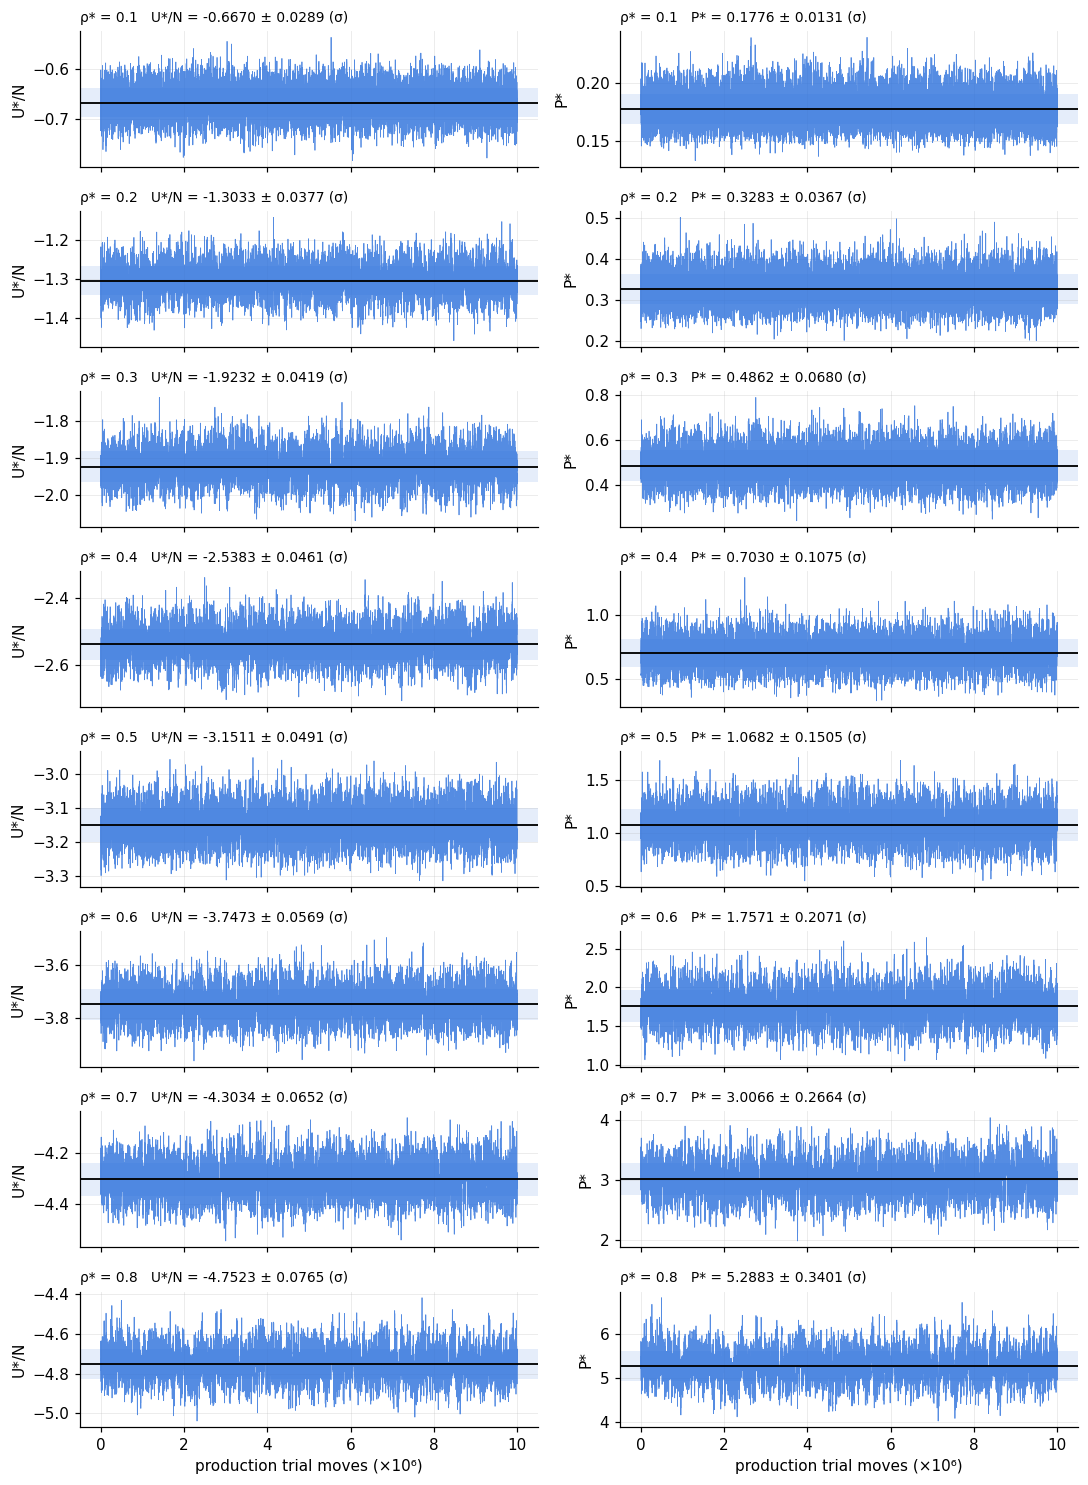

In [9]:
fig, axes = plt.subplots(len(rhos), 2, figsize=(10, 1.7 * len(rhos)), sharex=True, squeeze=False)
for i, rho in enumerate(rhos):
    row = summary.iloc[i]
    for j, (kind, mean, sig, lab) in enumerate([('energy', row.U, row.sigma_U, 'U*/N'),
                                                ('pressure', row.P, row.sigma_P, 'P*')]):
        ax = axes[i, j]
        data = load_xy(kind, rho)
        if data is None:
            continue
        ax.plot(data[:, 0] / 1e6, data[:, 1], color=C_SIM, lw=0.5, alpha=0.8)
        ax.axhline(mean, color='k', lw=1.2)
        ax.axhspan(mean - sig, mean + sig, color=C_SIM, alpha=0.12, lw=0)
        ax.set_ylabel(lab)
        ax.set_title(f'ρ* = {rho:g}   {lab} = {mean:.4f} ± {sig:.4f} (σ)', fontsize=9, loc='left')
axes[-1, 0].set_xlabel('production trial moves (×10⁶)')
axes[-1, 1].set_xlabel('production trial moves (×10⁶)')
fig.tight_layout()
plt.show()

## Exercise 3 & 6 — Radial distribution function g(r)

One curve per density (light → dark = low → high density). At low density g(r) is a single
peak near the potential minimum (r ≈ 2^{1/6} σ); as ρ* increases the first peak grows and a
second and third coordination shell appear, the signature of liquid-like order.

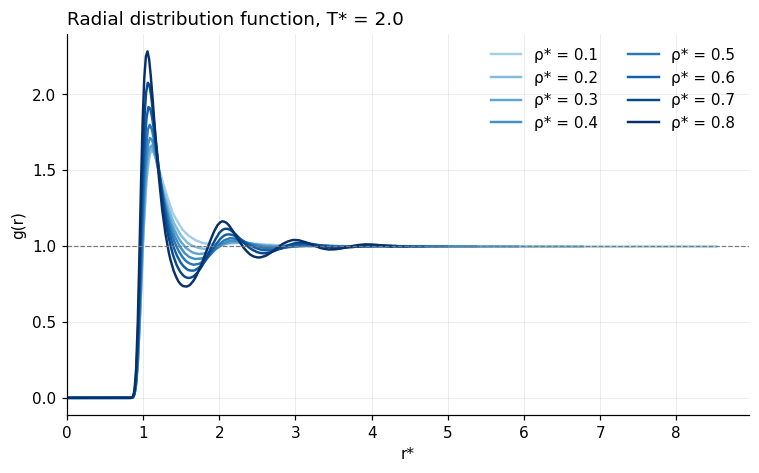

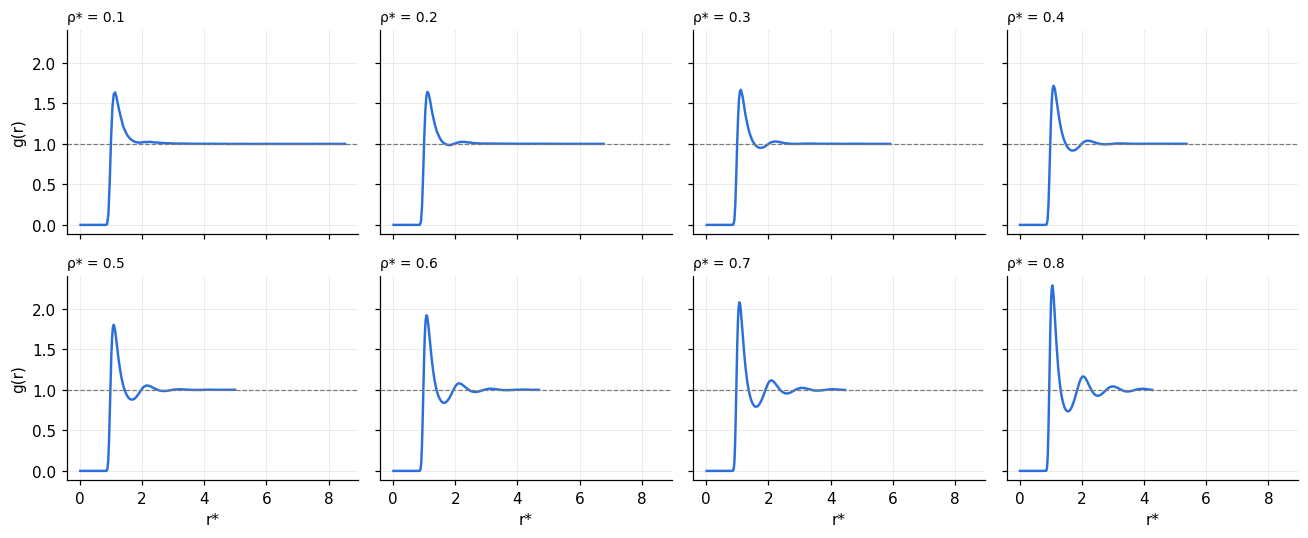

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for rho in rhos:
    g = load_xy('rdf', rho)
    if g is not None:
        ax.plot(g[:, 0], g[:, 1], color=COL[rho], label=f'ρ* = {rho:g}')
ax.axhline(1.0, color=C_IDEAL, lw=0.8, ls='--')
ax.set_xlabel('r*')
ax.set_ylabel('g(r)')
ax.set_xlim(0, None)
ax.set_title(f'Radial distribution function, T* = {T_STAR}', loc='left')
ax.legend(ncol=2)
plt.show()

# small multiples, one per density, same axes
n = len(rhos)
fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(12, 5), sharex=True, sharey=True, squeeze=False)
for ax, rho in zip(axes.flat, rhos):
    g = load_xy('rdf', rho)
    ax.plot(g[:, 0], g[:, 1], color=C_SIM)
    ax.axhline(1.0, color=C_IDEAL, lw=0.8, ls='--')
    ax.set_title(f'ρ* = {rho:g}', fontsize=9, loc='left')
for ax in axes[-1]:
    ax.set_xlabel('r*')
for ax in axes[:, 0]:
    ax.set_ylabel('g(r)')
for ax in axes.flat[n:]:
    ax.set_visible(False)
fig.tight_layout()
plt.show()

## Exercise 4 — Technical parameters and results

`σ_U`, `σ_P` are the standard deviations of the instantaneous values (fluctuations);
`err_U`, `err_P` are the errors of the mean from 10 block averages.
The last columns compare with Johnson et al. (1993), in units of the combined error.

In [11]:
tab = summary.merge(REF, on='rho', how='left')
tab['ΔU/err'] = (tab.U - tab.U_ref) / np.hypot(tab.err_U, tab.U_ref_err)
tab['ΔP/err'] = (tab.P - tab.P_ref) / np.hypot(tab.err_P, tab.P_ref_err)
cols = ['rho', 'ncycl', 'deltax', 'acc', 'rc', 'U', 'sigma_U', 'err_U', 'U_ref',
        'P', 'sigma_P', 'err_P', 'P_ref', 'ΔU/err', 'ΔP/err']
tab[cols].style.format({'deltax': '{:.3f}', 'acc': '{:.3f}', 'rc': '{:.2f}', 'U': '{:.4f}',
                        'sigma_U': '{:.4f}', 'err_U': '{:.4f}', 'U_ref': '{:.3f}', 'P': '{:.4f}',
                        'sigma_P': '{:.4f}', 'err_P': '{:.4f}', 'P_ref': '{:.4f}',
                        'ΔU/err': '{:+.1f}', 'ΔP/err': '{:+.1f}', 'ncycl': '{:.0e}'}, na_rep='—')

,rho,ncycl,deltax,acc,rc,U,sigma_U,err_U,U_ref,P,sigma_P,err_P,P_ref,ΔU/err,ΔP/err
0,0.100000,1e+07,8.550,0.547,5.00,-0.6670,0.0289,0.0004,-0.667,0.1776,0.0131,0.0001,0.1777,+0.0,-0.3
1,0.200000,1e+07,1.435,0.498,5.00,-1.3033,0.0377,0.0012,-1.306,0.3283,0.0367,0.0003,0.3290,+1.7,-1.1
2,0.300000,1e+07,0.875,0.496,5.00,-1.9232,0.0419,0.0015,—,0.4862,0.0680,0.0009,—,—,—
3,0.400000,1e+07,0.629,0.494,5.00,-2.5383,0.0461,0.0010,-2.538,0.7030,0.1075,0.0022,0.7050,-0.1,-0.8
4,0.500000,1e+07,0.471,0.500,5.00,-3.1511,0.0491,0.0011,-3.149,1.0682,0.1505,0.0029,1.0690,-0.9,-0.2
5,0.600000,1e+07,0.373,0.497,4.71,-3.7473,0.0569,0.0011,-3.746,1.7571,0.2071,0.0043,1.7560,-0.6,+0.1
6,0.700000,1e+07,0.298,0.498,4.47,-4.3034,0.0652,0.0020,-4.300,3.0066,0.2664,0.0080,3.0240,-1.2,-1.6
7,0.800000,1e+07,0.240,0.503,4.27,-4.7523,0.0765,0.0017,-4.753,5.2883,0.3401,0.0091,5.2800,+0.2,+0.6


## Exercise 5 — U* and P* versus ρ*, and the ideal-gas limit

Error bars are the errors of the mean (often smaller than the markers). The right panel shows the
compressibility factor Z = P/(ρ k_B T): the ideal gas has Z = 1, so the deviation from 1 measures
how good P = ρ k_B T is.

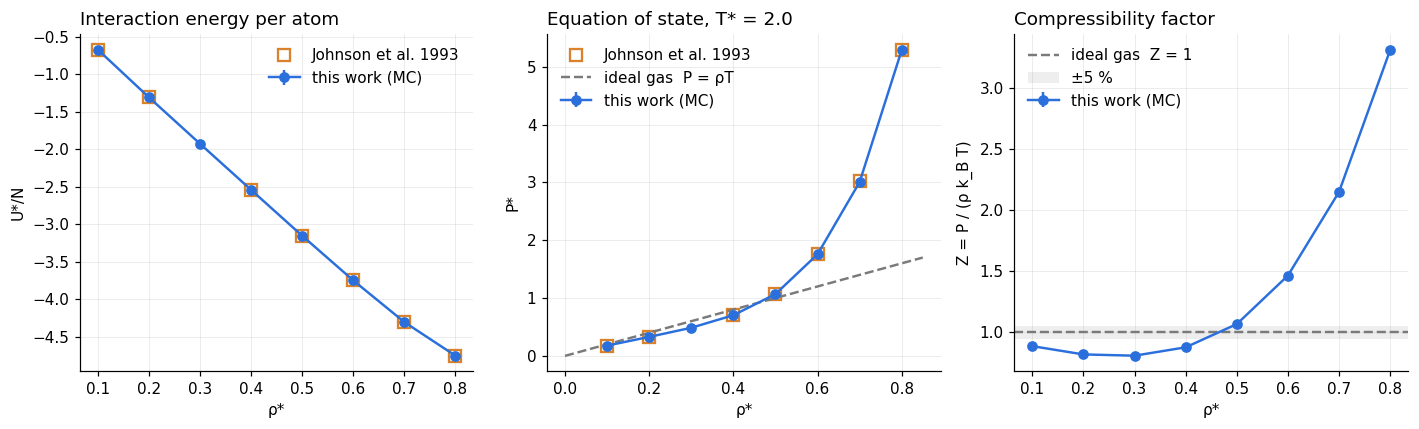

,rho,P_MC,P_ideal,Z,deviation %
0,0.100000,0.1776,0.2000,0.888,-11.2
1,0.200000,0.3283,0.4000,0.821,-17.9
2,0.300000,0.4862,0.6000,0.810,-19.0
3,0.400000,0.7030,0.8000,0.879,-12.1
4,0.500000,1.0682,1.0000,1.068,+6.8
5,0.600000,1.7571,1.2000,1.464,+46.4
6,0.700000,3.0066,1.4000,2.148,+114.8
7,0.800000,5.2883,1.6000,3.305,+230.5


|Z-1| <= 5%: not satisfied even at the lowest simulated density (rho* = 0.1)
|Z-1| <= 10%: not satisfied even at the lowest simulated density (rho* = 0.1)
|Z-1| <= 20%: holds from the lowest density up to rho* = 0.5


In [12]:
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(13, 4))

a1.errorbar(summary.rho, summary.U, yerr=summary.err_U, fmt='o-', color=C_SIM, ms=6, label='this work (MC)')
a1.plot(REF.rho, REF.U_ref, 's', mfc='none', color=C_REF, ms=8, mew=1.5, label='Johnson et al. 1993')
a1.set_xlabel('ρ*'); a1.set_ylabel('U*/N'); a1.set_title('Interaction energy per atom', loc='left')
a1.legend()

rr = np.linspace(0, 0.85, 100)
a2.errorbar(summary.rho, summary.P, yerr=summary.err_P, fmt='o-', color=C_SIM, ms=6, label='this work (MC)')
a2.plot(REF.rho, REF.P_ref, 's', mfc='none', color=C_REF, ms=8, mew=1.5, label='Johnson et al. 1993')
a2.plot(rr, rr * T_STAR, '--', color=C_IDEAL, label='ideal gas  P = ρT')
a2.set_xlabel('ρ*'); a2.set_ylabel('P*'); a2.set_title(f'Equation of state, T* = {T_STAR}', loc='left')
a2.legend()

Z = summary.P / (summary.rho * T_STAR)
Zerr = summary.err_P / (summary.rho * T_STAR)
a3.errorbar(summary.rho, Z, yerr=Zerr, fmt='o-', color=C_SIM, ms=6, label='this work (MC)')
a3.axhline(1.0, ls='--', color=C_IDEAL, label='ideal gas  Z = 1')
a3.axhspan(0.95, 1.05, color=C_IDEAL, alpha=0.12, lw=0, label='±5 %')
a3.set_xlabel('ρ*'); a3.set_ylabel('Z = P / (ρ k_B T)'); a3.set_title('Compressibility factor', loc='left')
a3.legend()

fig.tight_layout()
plt.show()

dev = pd.DataFrame({'rho': summary.rho, 'P_MC': summary.P, 'P_ideal': summary.rho * T_STAR,
                    'Z': Z, 'deviation %': 100 * (Z - 1)})
display(dev.style.format({'P_MC': '{:.4f}', 'P_ideal': '{:.4f}', 'Z': '{:.3f}', 'deviation %': '{:+.1f}'}))
for tol in (0.05, 0.10, 0.20):
    good = (abs(Z - 1) <= tol).values
    n_ok = len(good) if good.all() else int(np.argmin(good))   # contiguous range from the lowest density
    if n_ok == 0:
        print(f'|Z-1| <= {tol:.0%}: not satisfied even at the lowest simulated density (rho* = {summary.rho.iloc[0]:g})')
    else:
        print(f'|Z-1| <= {tol:.0%}: holds from the lowest density up to rho* = {summary.rho.iloc[n_ok - 1]:g}')

**Reading the ideal-gas question.** At low density Z < 1: the attractive tail of the LJ potential
dominates (at T* = 2 the second virial coefficient is negative), so P is *below* ρk_BT — already by
~11 % at ρ* = 0.1. Z returns to 1 near ρ* ≈ 0.47 only because attraction and repulsion cancel there;
that crossing is **not** ideal-gas behaviour (U*/N ≈ −3 is far from 0). Above ρ* ≈ 0.5 the repulsive core
dominates and P grows much faster than ρk_BT. The ideal-gas law is therefore only a good approximation
well below ρ* = 0.1 (Z → 1 as ρ* → 0); within the simulated range it is accurate to ~10–20 % at most up to ρ* ≈ 0.1–0.2.

## Exercise 7 — U and P from numerical integration of g(r)

$$\frac{U}{N} = 2\pi\rho\int_0^{r_c} u(r)\,g(r)\,r^2\,dr + \frac{U_{tail}}{N},\qquad
P = \rho k_BT - \frac{2\pi}{3}\rho^2\int_0^{r_c} \frac{du}{dr}\,g(r)\,r^3\,dr + P_{tail}$$

with $u(r) = 4(r^{-12}-r^{-6})$ and $du/dr = -48r^{-13} + 24r^{-7}$ in reduced units.
The integrals are cut at the same r_c used in the simulation and the same analytic tails
(which assume g = 1 beyond r_c) are added, so they estimate exactly the same quantities as
the direct averages of Exercise 4. Integration: trapezoidal rule over the histogram bin centres.
Differences come from the finite bin width of g(r) (the r⁻¹² wall is steep) and statistical noise.

,rho,U_direct,U_g(r),ΔU %,P_direct,P_g(r),ΔP %
0,0.100000,-0.6670,-0.6635,+0.52,0.1776,0.1795,+1.06
1,0.200000,-1.3033,-1.2987,+0.36,0.3283,0.3332,+1.50
2,0.300000,-1.9232,-1.9181,+0.27,0.4862,0.4945,+1.71
3,0.400000,-2.5383,-2.5322,+0.24,0.7030,0.7162,+1.87
4,0.500000,-3.1511,-3.1438,+0.23,1.0682,1.0873,+1.78
5,0.600000,-3.7473,-3.7385,+0.24,1.7571,1.7843,+1.55
6,0.700000,-4.3034,-4.2925,+0.25,3.0066,3.0449,+1.27
7,0.800000,-4.7523,-4.7391,+0.28,5.2883,5.3404,+0.99


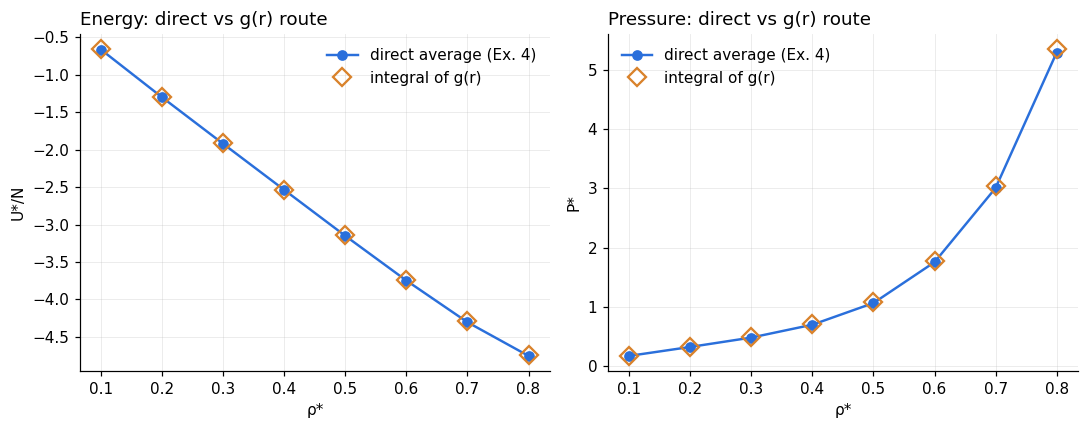

In [13]:
trapz = getattr(np, 'trapezoid', None) or np.trapz

def u_lj(r):
    return 4.0 * (r**-12 - r**-6)

def du_lj(r):
    return -48.0 * r**-13 + 24.0 * r**-7

def tails(rho, rc):
    ut = (8 * np.pi / 3) * rho * ((1 / 3) * rc**-9 - rc**-3)
    pt = (16 * np.pi / 3) * rho**2 * ((2 / 3) * rc**-9 - rc**-3)
    return ut, pt

rows = []
for _, s in summary.iterrows():
    g = load_xy('rdf', s.rho)
    r, gr = g[:, 0], g[:, 1]
    m = (r > 0) & (r <= s.rc)
    r, gr = r[m], gr[m]
    ut, pt = tails(s.rho, s.rc)
    U_int = 2 * np.pi * s.rho * trapz(u_lj(r) * gr * r**2, r) + ut
    P_int = s.rho * T_STAR - (2 * np.pi / 3) * s.rho**2 * trapz(du_lj(r) * gr * r**3, r) + pt
    rows.append({'rho': s.rho, 'U_direct': s.U, 'U_g(r)': U_int, 'ΔU %': 100 * (U_int - s.U) / abs(s.U),
                 'P_direct': s.P, 'P_g(r)': P_int, 'ΔP %': 100 * (P_int - s.P) / abs(s.P)})
cmp7 = pd.DataFrame(rows)
display(cmp7.style.format({'U_direct': '{:.4f}', 'U_g(r)': '{:.4f}', 'ΔU %': '{:+.2f}',
                           'P_direct': '{:.4f}', 'P_g(r)': '{:.4f}', 'ΔP %': '{:+.2f}'}))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4))
a1.plot(cmp7.rho, cmp7.U_direct, 'o-', color=C_SIM, ms=6, label='direct average (Ex. 4)')
a1.plot(cmp7.rho, cmp7['U_g(r)'], 'D', mfc='none', color=C_REF, ms=8, mew=1.5, label='integral of g(r)')
a1.set_xlabel('ρ*'); a1.set_ylabel('U*/N'); a1.set_title('Energy: direct vs g(r) route', loc='left'); a1.legend()
a2.plot(cmp7.rho, cmp7.P_direct, 'o-', color=C_SIM, ms=6, label='direct average (Ex. 4)')
a2.plot(cmp7.rho, cmp7['P_g(r)'], 'D', mfc='none', color=C_REF, ms=8, mew=1.5, label='integral of g(r)')
a2.set_xlabel('ρ*'); a2.set_ylabel('P*'); a2.set_title('Pressure: direct vs g(r) route', loc='left'); a2.legend()
fig.tight_layout()
plt.show()